In [4]:
%matplotlib inline

import os
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from dateutil.tz import tzutc
from dateutil.parser import parse
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from datetime import datetime, timezone
from py_wave_runup import models


## 1. Load Data Files


In [2]:
# Load Shorescan Output
SS_PATH = 'C:/Users/cvolpano/shorescan_processing/DATA/Shorescan_TWL_viewer_Transect70_c1_sensor_clean.csv'
PUV_PATH = 'C:/Users/cvolpano/shorescan_processing/DATA/sig1000_waves_ALL.csv'

df_ss=pd.read_csv(SS_PATH)
df_ss['dt0']=pd.to_datetime(df_ss['dt0'],utc=True)
df_ss = df_ss.set_index('dt0')
df_ss = df_ss.drop(columns=['transect','camera','filename','timestamp'])

print(f"Shorescan Data Loaded: {len(df_ss)} rows")
print(f"  {df_ss.index.min()} → {df_ss.index.max()}")
# Load pressure sensor data
def load_puv_csv(path):
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    df = df.rename(columns={"wh_4061": "Hs", "wp_peak": "Tp"})
    df = df.apply(pd.to_numeric, errors="coerce")
    df["Hs"] = df["Hs"].where(df["Hs"] < 99.0)
    df["Tp"] = df["Tp"].where(df["Tp"] < 99.0)
    return df

puv = load_puv_csv(PUV_PATH)
puv = puv.resample("1h").mean() 

print(f"PUV Data Loaded: {len(puv)} rows")
print(f"  {puv.index.min()} → {puv.index.max()}")


Shorescan Data Loaded: 1128 rows
  2024-10-15 11:00:00+00:00 → 2025-03-13 20:30:00+00:00
PUV Data Loaded: 2182 rows
  2024-12-09 18:00:00 → 2025-03-10 15:00:00


# 2. Align time indices of both dataframes

> index.union() — merges both time indices into one sorted list of timestamps. \
> reindex() — adds missing timestamps to each DataFrame (with NaNs). \
> interpolate(method='time') — fills NaNs by interpolating based on time. \
> concat() — merges the two interpolated DataFrames side-by-side.

datetime64[us]


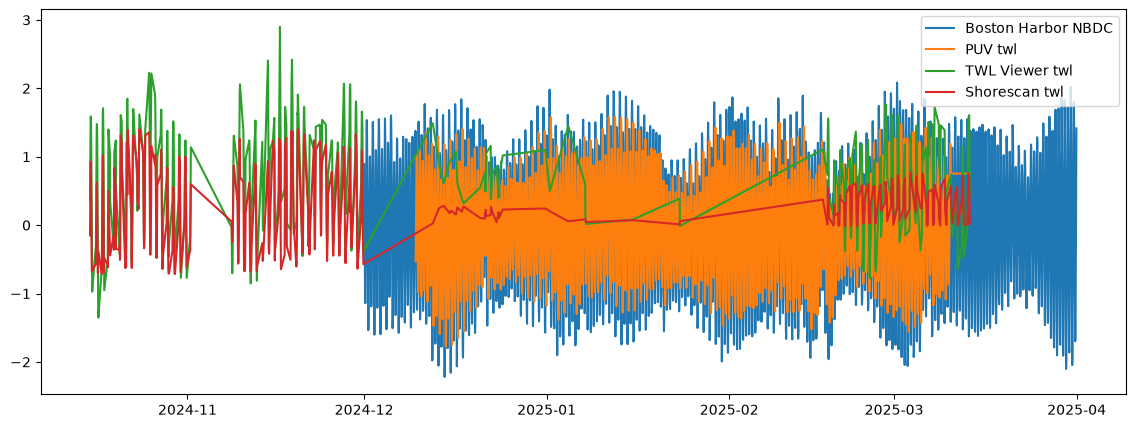

In [54]:
df1 = puv
df2 = df_ss
df1.index = pd.to_datetime(df1.index,utc=True)
df2.index = pd.to_datetime(df2.index,utc=True)
combined_index = pd.date_range(start=min(df1.index.min(), df2.index.min()),
                               end=max(df1.index.max(), df2.index.max()),
                               freq='h')

# Step 2: Reindex both DataFrames to the combined index
df1_reindexed = df1.reindex(combined_index)
df2_reindexed = df2.reindex(combined_index)

# Step 3: Interpolate missing values (linear interpolation in time)
df1_interp = df1_reindexed.interpolate(method='time')
df2_interp = df2_reindexed.interpolate(method='time')


# Optional: Combine into one DataFrame
aligned_df = pd.concat([df1_interp, df2_interp], axis=1)


WL_PATH = "E:/cvolpano/shorescan_processing/DATA/CO-OPS_8443970_met_BostonHarbor_12012024-03012025_WL.csv"
df_wl=pd.read_csv(WL_PATH)
df_wl["datetime"] = pd.to_datetime(
    df_wl["Date"] + " " + df_wl["Time (LST)"],
    errors="coerce",           # Invalid values become NaT
    format=None,
    unit="ns"              
)
print(df_wl['datetime'].dtype)




fig,ax = plt.subplots(figsize=[14,5])
plt.plot(df_wl['datetime'],df_wl['Verified (m)'],label="Boston Harbor NBDC")
plt.plot(aligned_df['water_level'],label="PUV twl")
plt.plot(aligned_df['cc_twl'],label='TWL Viewer twl')
plt.plot(aligned_df['ss_twl_mean'],label="Shorescan twl")

plt.legend()
plt.show()

Text(0, 0.5, 'Stockdon 2006 PUV Sensor Runup')

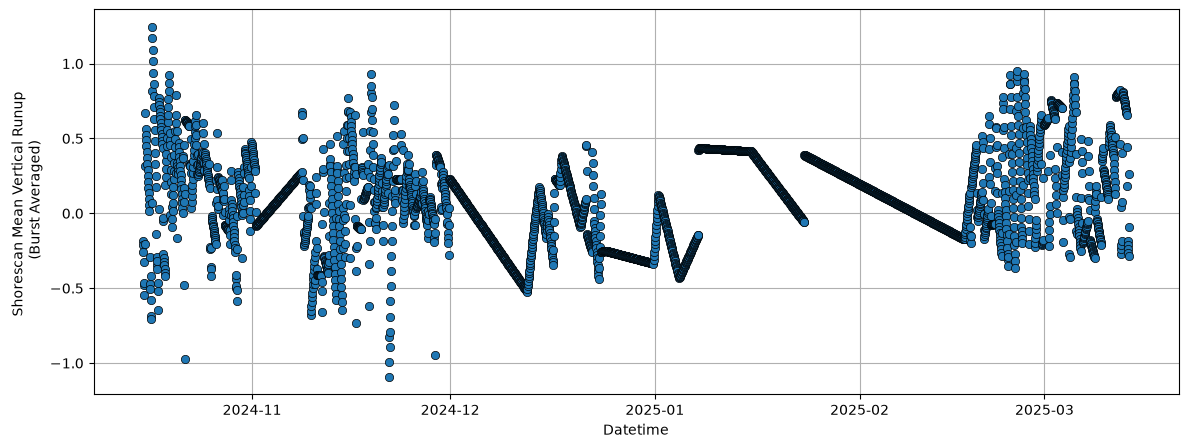

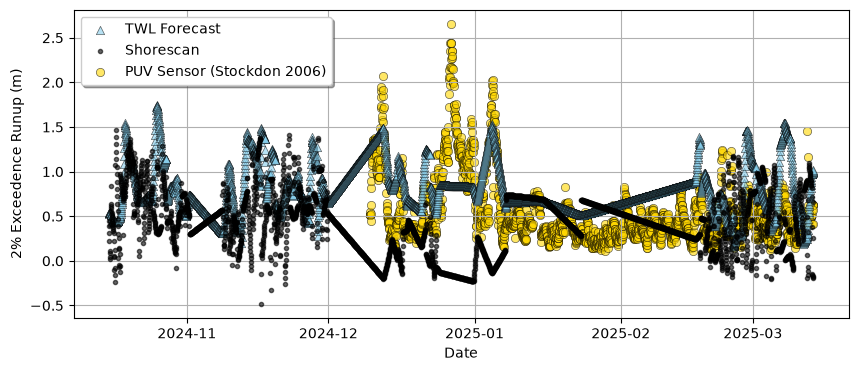

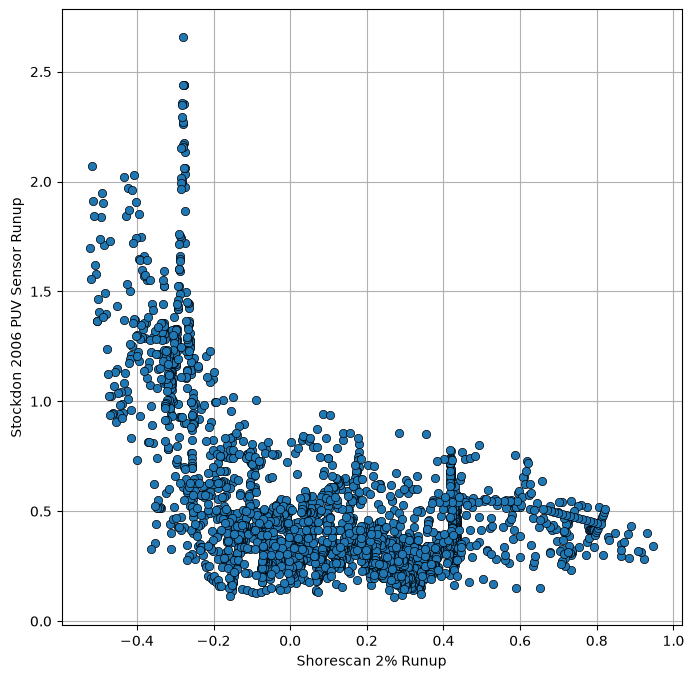

In [31]:
fig,ax = plt.subplots(figsize=[14,5])
plt.grid(True,zorder=0)
plt.scatter(aligned_df.index,aligned_df['ss_zrunup_mean'],edgecolor='k',linewidths=.5,zorder=5)
plt.xlabel('Datetime')
plt.ylabel('Shorescan Mean Vertical Runup \n (Burst Averaged)')

datelim = pd.to_datetime(['10-01-2024','03-30-2025'])
datelim = datelim.tz_localize(
    "US/Eastern",
    ambiguous="NaT",
    nonexistent="shift_forward"
)
aligned_df = aligned_df.loc[datelim[0]:datelim[1]]
model_sto06 = models.Stockdon2006(Hs=aligned_df['Hs'], Tp=aligned_df['Tp'], beta=aligned_df['beta06'])

model_sto06.R2     # 2.54
model_sto06.setup  # 0.96
model_sto06.sinc   # 2.06
model_sto06.sig    # 1.65

fig, ax = plt.subplots(figsize=[10,4])
plt.grid(True,zorder=0)

plt.scatter(aligned_df.index,aligned_df['cc_ru_2pct'],edgecolor='k',linewidth=0.5,marker = '^',zorder=2,alpha=0.6,c='skyblue',label='TWL Forecast')
plt.scatter(aligned_df.index,aligned_df['ss_ru_2pct'],marker = '.',zorder=3,alpha=0.6,c='k',label='Shorescan')
plt.scatter(aligned_df.index,model_sto06.R2,edgecolor='k',linewidths=.5,zorder=0,alpha=0.6,c='gold',label='PUV Sensor (Stockdon 2006)')
plt.legend(
    loc="upper left",       # Position of legend
    fontsize=10,            # Font size   # Legend title
    shadow=True,            # Shadow effect
    fancybox=True           # Rounded box
)
plt.xlabel('Date')
plt.ylabel('2% Exceedence Runup (m)')

fig,ax = plt.subplots(figsize=[8,8])
plt.grid(True,zorder=0)
plt.scatter(aligned_df['ss_zrunup_mean'],model_sto06.R2,edgecolor='k',linewidths=.5,zorder=5)
plt.xlabel('Shorescan 2% Runup')
plt.ylabel('Stockdon 2006 PUV Sensor Runup')


